
# German Electricity Demand Forecasting

## 01 — Data Inspection

**Data source:** Bundesnetzagentur — SMARD  
**Period:** 2023–2025  
**Objective:** Develop a machine learning model to forecast Germany's electricity demand one hour ahead.

### Goals
- Understand the raw dataset structure.
- Inspect data types and missing values.
- Verify timestamps and electricity consumption units.
- Identify potential data-quality issues before modelling.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original SMARD electricity dataset
file_path = "data/raw/electricity_data.csv"

df = pd.read_csv(file_path, sep=";")

# Display dataset dimensions and first five rows
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (26304, 6)


,Start date,End date,grid load [MWh] Calculated resolutions,Grid load incl. hydro pumped storage [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Residual load [MWh] Calculated resolutions
0,"Jan 1, 2023 12:00 AM","Jan 1, 2023 1:00 AM","38,346.00","40,422.75","2,076.75","6,337.75"
1,"Jan 1, 2023 1:00 AM","Jan 1, 2023 2:00 AM","37,777.25","39,545.00","1,767.75","4,601.75"
2,"Jan 1, 2023 2:00 AM","Jan 1, 2023 3:00 AM","36,939.75","39,990.00","3,050.25","3,581.00"
3,"Jan 1, 2023 3:00 AM","Jan 1, 2023 4:00 AM","35,932.50","39,636.50","3,704.00","4,973.75"
4,"Jan 1, 2023 4:00 AM","Jan 1, 2023 5:00 AM","35,486.25","39,287.00","3,800.75","5,082.75"


In [2]:

# Inspect column names and data types
print("COLUMN INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isna().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Display the last five rows
display(df.tail())


COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26304 entries, 0 to 26303
Data columns (total 6 columns):
 #   Column                                                             Non-Null Count  Dtype 
---  ------                                                             --------------  ----- 
 0   Start date                                                         26304 non-null  object
 1   End date                                                           26304 non-null  object
 2   grid load [MWh] Calculated resolutions                             26304 non-null  object
 3   Grid load incl. hydro pumped storage [MWh] Calculated resolutions  26304 non-null  object
 4   Hydro pumped storage [MWh] Calculated resolutions                  26304 non-null  object
 5   Residual load [MWh] Calculated resolutions                         26304 non-null  object
dtypes: object(6)
memory usage: 1.2+ MB

MISSING VALUES
Start date                                               

,Start date,End date,grid load [MWh] Calculated resolutions,Grid load incl. hydro pumped storage [MWh] Calculated resolutions,Hydro pumped storage [MWh] Calculated resolutions,Residual load [MWh] Calculated resolutions
26299,"Dec 31, 2025 7:00 PM","Dec 31, 2025 8:00 PM","55,505.61","55,611.81",106.20,"22,527.41"
26300,"Dec 31, 2025 8:00 PM","Dec 31, 2025 9:00 PM","52,297.32","52,699.30",401.98,"18,595.66"
26301,"Dec 31, 2025 9:00 PM","Dec 31, 2025 10:00 PM","50,355.34","51,596.46","1,241.12","15,425.71"
26302,"Dec 31, 2025 10:00 PM","Dec 31, 2025 11:00 PM","49,025.54","49,526.69",501.15,"15,306.56"
26303,"Dec 31, 2025 11:00 PM","Jan 1, 2026 12:00 AM","47,434.60","47,728.69",294.10,"13,054.51"


In [3]:

# Select our prediction target
target_col = "grid load [MWh] Calculated resolutions"

# Inspect the original values
print("Original values:")
print(df[target_col].head(10))

# Check for missing-value symbols
print("\nDash values:", (df[target_col] == "-").sum())

# Convert German-formatted numbers to numeric values
df["grid_load_mwh"] = pd.to_numeric(
    df[target_col]
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

# Verify conversion
print("\nMissing values after conversion:")
print(df["grid_load_mwh"].isna().sum())

print("\nSummary statistics:")
display(df["grid_load_mwh"].describe())


Original values:
0    38,346.00
1    37,777.25
2    36,939.75
3    35,932.50
4    35,486.25
5    35,647.25
6    35,231.75
7    36,172.25
8    36,829.25
9    39,226.50
Name: grid load [MWh] Calculated resolutions, dtype: object

Dash values: 0

Missing values after conversion:
0

Summary statistics:


count    26304.000000
mean        52.832355
std          9.131089
min         30.902750
25%         45.328938
50%         52.882625
75%         59.712562
max         75.635210
Name: grid_load_mwh, dtype: float64

In [4]:

# Correct conversion: comma is the thousands separator
df["grid_load_mwh"] = pd.to_numeric(
    df[target_col].str.replace(",", "", regex=False),
    errors="coerce"
)

# Verify corrected values
print("First five values:")
print(df["grid_load_mwh"].head())

print("\nMissing values:", df["grid_load_mwh"].isna().sum())

print("\nSummary statistics:")
display(df["grid_load_mwh"].describe())


First five values:
0    38346.00
1    37777.25
2    36939.75
3    35932.50
4    35486.25
Name: grid_load_mwh, dtype: float64

Missing values: 0

Summary statistics:


count    26304.000000
mean     52832.355277
std       9131.088611
min      30902.750000
25%      45328.937500
50%      52882.625000
75%      59712.562500
max      75635.210000
Name: grid_load_mwh, dtype: float64

In [5]:

# Inspect the original timestamp format
print("Original timestamps:")
display(df[["Start date", "End date"]].head())

# Convert text into datetime values
df["timestamp"] = pd.to_datetime(
    df["Start date"],
    format="%b %d, %Y %I:%M %p",
    errors="coerce"
)

# Verify the conversion
print("\nInvalid timestamps:", df["timestamp"].isna().sum())
print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

# Check for repeated timestamps
print("Repeated timestamps:", df["timestamp"].duplicated().sum())

display(df[["timestamp", "grid_load_mwh"]].head())


Original timestamps:


,Start date,End date
0,"Jan 1, 2023 12:00 AM","Jan 1, 2023 1:00 AM"
1,"Jan 1, 2023 1:00 AM","Jan 1, 2023 2:00 AM"
2,"Jan 1, 2023 2:00 AM","Jan 1, 2023 3:00 AM"
3,"Jan 1, 2023 3:00 AM","Jan 1, 2023 4:00 AM"
4,"Jan 1, 2023 4:00 AM","Jan 1, 2023 5:00 AM"



Invalid timestamps: 0
First timestamp: 2023-01-01 00:00:00
Last timestamp: 2025-12-31 23:00:00
Repeated timestamps: 3


,timestamp,grid_load_mwh
0,2023-01-01 00:00:00,38346.00
1,2023-01-01 01:00:00,37777.25
2,2023-01-01 02:00:00,36939.75
3,2023-01-01 03:00:00,35932.50
4,2023-01-01 04:00:00,35486.25


In [6]:

# Display repeated timestamps, including both occurrences
repeated = df[
    df["timestamp"].duplicated(keep=False)
]

print("Repeated timestamp records:")
display(
    repeated[
        ["timestamp", "grid_load_mwh"]
    ]
)

# Check whether the original data is ordered
print("\nTimestamps in chronological order:")
print(df["timestamp"].is_monotonic_increasing)

# Find any intervals that are not exactly one hour apart
df["time_difference"] = df["timestamp"].diff()

unusual_intervals = df[
    df["time_difference"] != pd.Timedelta(hours=1)
]

print("\nUnusual time intervals:")
display(
    unusual_intervals[
        ["timestamp", "time_difference"]
    ]
)


Repeated timestamp records:


,timestamp,grid_load_mwh
7225,2023-10-29 02:00:00,37379.25
7226,2023-10-29 02:00:00,37440.50
15961,2024-10-27 02:00:00,35966.00
15962,2024-10-27 02:00:00,35613.25
24697,2025-10-26 02:00:00,40843.99
24698,2025-10-26 02:00:00,40237.03



Timestamps in chronological order:
True

Unusual time intervals:


,timestamp,time_difference
0,2023-01-01 00:00:00,NaT
2018,2023-03-26 03:00:00,0 days 02:00:00
7226,2023-10-29 02:00:00,0 days 00:00:00
10922,2024-03-31 03:00:00,0 days 02:00:00
15962,2024-10-27 02:00:00,0 days 00:00:00
19658,2025-03-30 03:00:00,0 days 02:00:00
24698,2025-10-26 02:00:00,0 days 00:00:00


In [7]:

# Convert local German timestamps into timezone-aware timestamps
df["timestamp_berlin"] = (
    df["timestamp"]
    .dt.tz_localize(
        "Europe/Berlin",
        ambiguous="infer",
        nonexistent="raise"
    )
)

# Convert Berlin time into UTC
df["timestamp_utc"] = (
    df["timestamp_berlin"].dt.tz_convert("UTC")
)

# Verify the conversion
print("Repeated UTC timestamps:",
      df["timestamp_utc"].duplicated().sum())

print("Unusual UTC intervals:",
      (df["timestamp_utc"].diff().dropna()
       != pd.Timedelta(hours=1)).sum())

print("First UTC timestamp:", df["timestamp_utc"].min())
print("Last UTC timestamp:", df["timestamp_utc"].max())

display(
    df[["timestamp", "timestamp_berlin",
        "timestamp_utc", "grid_load_mwh"]].head()
)


Repeated UTC timestamps: 0
Unusual UTC intervals: 0
First UTC timestamp: 2022-12-31 23:00:00+00:00
Last UTC timestamp: 2025-12-31 22:00:00+00:00


,timestamp,timestamp_berlin,timestamp_utc,grid_load_mwh
0,2023-01-01 00:00:00,2023-01-01 00:00:00+01:00,2022-12-31 23:00:00+00:00,38346.00
1,2023-01-01 01:00:00,2023-01-01 01:00:00+01:00,2023-01-01 00:00:00+00:00,37777.25
2,2023-01-01 02:00:00,2023-01-01 02:00:00+01:00,2023-01-01 01:00:00+00:00,36939.75
3,2023-01-01 03:00:00,2023-01-01 03:00:00+01:00,2023-01-01 02:00:00+00:00,35932.50
4,2023-01-01 04:00:00,2023-01-01 04:00:00+01:00,2023-01-01 03:00:00+00:00,35486.25


In [8]:

# Create a clean forecasting dataframe
ml_df = df[
    ["timestamp_utc", "timestamp_berlin", "grid_load_mwh"]
].copy()

# Extract calendar features using German local time
ml_df["hour"] = ml_df["timestamp_berlin"].dt.hour
ml_df["day_of_week"] = ml_df["timestamp_berlin"].dt.dayofweek
ml_df["month"] = ml_df["timestamp_berlin"].dt.month

# Weekend indicator: Saturday=5, Sunday=6
ml_df["is_weekend"] = (
    ml_df["day_of_week"] >= 5
).astype(int)

# Inspect our new features
display(ml_df.head(10))

print("Dataset shape:", ml_df.shape)


,timestamp_utc,timestamp_berlin,grid_load_mwh,hour,day_of_week,month,is_weekend
0,2022-12-31 23:00:00+00:00,2023-01-01 00:00:00+01:00,38346.00,0,6,1,1
1,2023-01-01 00:00:00+00:00,2023-01-01 01:00:00+01:00,37777.25,1,6,1,1
2,2023-01-01 01:00:00+00:00,2023-01-01 02:00:00+01:00,36939.75,2,6,1,1
3,2023-01-01 02:00:00+00:00,2023-01-01 03:00:00+01:00,35932.50,3,6,1,1
4,2023-01-01 03:00:00+00:00,2023-01-01 04:00:00+01:00,35486.25,4,6,1,1
5,2023-01-01 04:00:00+00:00,2023-01-01 05:00:00+01:00,35647.25,5,6,1,1
6,2023-01-01 05:00:00+00:00,2023-01-01 06:00:00+01:00,35231.75,6,6,1,1
7,2023-01-01 06:00:00+00:00,2023-01-01 07:00:00+01:00,36172.25,7,6,1,1
8,2023-01-01 07:00:00+00:00,2023-01-01 08:00:00+01:00,36829.25,8,6,1,1
9,2023-01-01 08:00:00+00:00,2023-01-01 09:00:00+01:00,39226.50,9,6,1,1


Dataset shape: (26304, 7)


In [9]:

# Ensure observations are in chronological order
ml_df = ml_df.sort_values("timestamp_utc").reset_index(drop=True)

# Create historical electricity demand features
ml_df["lag_1"] = ml_df["grid_load_mwh"].shift(1)
ml_df["lag_24"] = ml_df["grid_load_mwh"].shift(24)
ml_df["lag_168"] = ml_df["grid_load_mwh"].shift(168)

# Inspect the resulting features
display(
    ml_df[
        ["timestamp_berlin", "grid_load_mwh",
         "lag_1", "lag_24", "lag_168"]
    ].iloc[168:175]
)

# Check missing values created by shifting
print("\nMissing values in lag features:")
print(ml_df[["lag_1", "lag_24", "lag_168"]].isna().sum())


,timestamp_berlin,grid_load_mwh,lag_1,lag_24,lag_168
168,2023-01-08 00:00:00+01:00,42509.00,44757.25,43201.00,38346.00
169,2023-01-08 01:00:00+01:00,40708.50,42509.00,41185.25,37777.25
170,2023-01-08 02:00:00+01:00,39829.75,40708.50,40162.25,36939.75
171,2023-01-08 03:00:00+01:00,40059.50,39829.75,39778.25,35932.50
172,2023-01-08 04:00:00+01:00,40147.00,40059.50,40120.75,35486.25
173,2023-01-08 05:00:00+01:00,40020.00,40147.00,40901.75,35647.25
174,2023-01-08 06:00:00+01:00,39918.75,40020.00,41720.50,35231.75



Missing values in lag features:
lag_1        1
lag_24      24
lag_168    168
dtype: int64


In [10]:

# Remove rows without sufficient historical data
ml_df = ml_df.dropna(
    subset=["lag_1", "lag_24", "lag_168"]
).copy()

# Split chronologically using Berlin calendar years
years = ml_df["timestamp_berlin"].dt.year

train_df = ml_df[years == 2023].copy()
val_df = ml_df[years == 2024].copy()
test_df = ml_df[years == 2025].copy()

# Select model inputs
features = [
    "hour", "day_of_week", "month", "is_weekend",
    "lag_1", "lag_24", "lag_168"
]

target = "grid_load_mwh"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nMissing feature values:")
print(X_train.isna().sum().sum())
print(X_val.isna().sum().sum())
print(X_test.isna().sum().sum())


Training observations: 8592
Validation observations: 8784
Testing observations: 8760

Missing feature values:
0
0
0


In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: predict demand using the previous hour
baseline_val_pred = val_df["lag_1"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_val, baseline_val_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_val_pred)
)

# Display results
print("PERSISTENCE BASELINE — VALIDATION 2024")
print(f"MAE:  {baseline_mae:,.2f} MWh")
print(f"RMSE: {baseline_rmse:,.2f} MWh")


PERSISTENCE BASELINE — VALIDATION 2024
MAE:  1,757.88 MWh
RMSE: 2,319.90 MWh


In [12]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Build a pipeline with scaling and Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train using 2023 data only
ridge_model.fit(X_train, y_train)

# Predict electricity demand for 2024
ridge_val_pred = ridge_model.predict(X_val)

# Evaluate predictions
ridge_mae = mean_absolute_error(y_val, ridge_val_pred)
ridge_rmse = np.sqrt(
    mean_squared_error(y_val, ridge_val_pred)
)

print("RIDGE REGRESSION — VALIDATION 2024")
print(f"MAE:  {ridge_mae:,.2f} MWh")
print(f"RMSE: {ridge_rmse:,.2f} MWh")

print("\nBASELINE COMPARISON")
print(f"Baseline MAE: {baseline_mae:,.2f} MWh")
print(f"Ridge MAE:    {ridge_mae:,.2f} MWh")


RIDGE REGRESSION — VALIDATION 2024
MAE:  1,398.80 MWh
RMSE: 1,842.12 MWh

BASELINE COMPARISON
Baseline MAE: 1,757.88 MWh
Ridge MAE:    1,398.80 MWh


In [13]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train on 2023
rf_model.fit(X_train, y_train)

# Predict 2024 electricity demand
rf_val_pred = rf_model.predict(X_val)

# Evaluate
rf_mae = mean_absolute_error(y_val, rf_val_pred)
rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_val_pred)
)

print("RANDOM FOREST — VALIDATION 2024")
print(f"MAE:  {rf_mae:,.2f} MWh")
print(f"RMSE: {rf_rmse:,.2f} MWh")

print("\nMODEL COMPARISON")
print(f"Baseline MAE: {baseline_mae:,.2f}")
print(f"Ridge MAE:    {ridge_mae:,.2f}")
print(f"Forest MAE:   {rf_mae:,.2f}")


RANDOM FOREST — VALIDATION 2024
MAE:  604.18 MWh
RMSE: 848.43 MWh

MODEL COMPARISON
Baseline MAE: 1,757.88
Ridge MAE:    1,398.80
Forest MAE:   604.18


In [14]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Initialize Gradient Boosting model
gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.05,
    random_state=42
)

# Train using 2023 data
gb_model.fit(X_train, y_train)

# Predict 2024 demand
gb_val_pred = gb_model.predict(X_val)

# Evaluate
gb_mae = mean_absolute_error(y_val, gb_val_pred)
gb_rmse = np.sqrt(
    mean_squared_error(y_val, gb_val_pred)
)

# Compare all models
results = pd.DataFrame({
    "Model": [
        "Persistence",
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        baseline_mae, ridge_mae,
        rf_mae, gb_mae
    ],
    "RMSE": [
        baseline_rmse, ridge_rmse,
        rf_rmse, gb_rmse
    ]
})

display(results.sort_values("MAE"))


,Model,MAE,RMSE
3,Gradient Boosting,514.828682,697.040784
2,Random Forest,604.180645,848.425435
1,Ridge Regression,1398.796538,1842.120534
0,Persistence,1757.880202,2319.904134


In [15]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.ensemble import HistGradientBoostingRegressor

# Create chronological cross-validation folds
tscv = TimeSeriesSplit(n_splits=5)

# Use the same Gradient Boosting settings
cv_model = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=31,
    learning_rate=0.05,
    random_state=42
)

# Evaluate across five chronological folds
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=tscv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

cv_mae = -cv_results["test_MAE"]
cv_rmse = -cv_results["test_RMSE"]

print("TIME-SERIES CROSS-VALIDATION — 2023")
print("MAE by fold:", np.round(cv_mae, 2))
print("RMSE by fold:", np.round(cv_rmse, 2))

print(f"\nMean CV MAE:  {cv_mae.mean():,.2f} MWh")
print(f"Mean CV RMSE: {cv_rmse.mean():,.2f} MWh")
print(f"MAE Std Dev:  {cv_mae.std():,.2f} MWh")


TIME-SERIES CROSS-VALIDATION — 2023
MAE by fold: [1460.84  664.28  440.89  581.46  772.36]
RMSE by fold: [2584.87  922.83  562.58  775.57 1031.  ]

Mean CV MAE:  783.97 MWh
Mean CV RMSE: 1,175.37 MWh
MAE Std Dev:  355.34 MWh


In [16]:

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor

# Define hyperparameter options
param_grid = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [10, 20, 30],
    "l2_regularization": [0.0, 0.1]
}

# Chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Set up randomized hyperparameter search
search = RandomizedSearchCV(
    estimator=HistGradientBoostingRegressor(
        random_state=42
    ),
    param_distributions=param_grid,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# Tune using 2023 training data only
search.fit(X_train, y_train)

print("BEST HYPERPARAMETERS:")
print(search.best_params_)

print("\nBEST CROSS-VALIDATION MAE:")
print(f"{-search.best_score_:,.2f} MWh")


BEST HYPERPARAMETERS:
{'min_samples_leaf': 10, 'max_leaf_nodes': 31, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 0.0}

BEST CROSS-VALIDATION MAE:
770.09 MWh


In [17]:

# Get the best model from hyperparameter tuning
tuned_model = search.best_estimator_

# Predict electricity demand for 2024
tuned_val_pred = tuned_model.predict(X_val)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_val, tuned_val_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_val_pred))

# Compare original and tuned models
comparison = pd.DataFrame({
    "Model": ["Original Gradient Boosting", "Tuned Gradient Boosting"],
    "MAE (MWh)": [gb_mae, tuned_mae],
    "RMSE (MWh)": [gb_rmse, tuned_rmse]
})

display(comparison)

print("\nMAE improvement after tuning:")
print(f"{gb_mae - tuned_mae:,.2f} MWh")


,Model,MAE (MWh),RMSE (MWh)
0,Original Gradient Boosting,514.828682,697.040784
1,Tuned Gradient Boosting,495.307202,671.642172



MAE improvement after tuning:
19.52 MWh


In [18]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Combine 2023 and 2024 for final training
X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

# Create a fresh copy of our selected model
final_model = clone(tuned_model)

# Train on 2023–2024
final_model.fit(X_final_train, y_final_train)

# Evaluate once on unseen 2025 data
final_pred = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))

# Persistence baseline on the same test period
test_baseline_pred = test_df["lag_1"]

test_baseline_mae = mean_absolute_error(
    y_test, test_baseline_pred
)

test_baseline_rmse = np.sqrt(
    mean_squared_error(y_test, test_baseline_pred)
)

print("FINAL TEST RESULTS — 2025")
print(f"Gradient Boosting MAE:  {final_mae:,.2f} MWh")
print(f"Gradient Boosting RMSE: {final_rmse:,.2f} MWh")

print("\nPERSISTENCE BASELINE — 2025")
print(f"Baseline MAE:  {test_baseline_mae:,.2f} MWh")
print(f"Baseline RMSE: {test_baseline_rmse:,.2f} MWh")

improvement = (
    (test_baseline_mae - final_mae)
    / test_baseline_mae * 100
)

print(f"\nMAE reduction vs baseline: {improvement:.2f}%")


FINAL TEST RESULTS — 2025
Gradient Boosting MAE:  500.46 MWh
Gradient Boosting RMSE: 666.45 MWh

PERSISTENCE BASELINE — 2025
Baseline MAE:  1,779.00 MWh
Baseline RMSE: 2,342.67 MWh

MAE reduction vs baseline: 71.87%


TOP 10 LARGEST PREDICTION ERRORS


,timestamp_berlin,grid_load_mwh,hour,day_of_week,month,predicted_mwh,error,absolute_error
17550,2025-01-01 06:00:00+01:00,43176.00,6,2,1,48862.712638,-5686.712638,5686.712638
26166,2025-12-26 06:00:00+01:00,43066.94,6,4,12,47621.316050,-4554.376050,4554.376050
23756,2025-09-16 21:00:00+02:00,50916.21,21,1,9,54701.420199,-3785.210199,3785.210199
26238,2025-12-29 06:00:00+01:00,49647.32,6,0,12,53390.967266,-3743.647266,3743.647266
19378,2025-03-18 10:00:00+01:00,62698.68,10,1,3,66017.447843,-3318.767843,3318.767843
20385,2025-04-29 10:00:00+02:00,57827.86,10,1,4,61014.522789,-3186.662789,3186.662789
17551,2025-01-01 07:00:00+01:00,43525.00,7,2,1,46698.761821,-3173.761821,3173.761821
26118,2025-12-24 06:00:00+01:00,46201.47,6,2,12,49356.798942,-3155.328942,3155.328942
23241,2025-08-26 10:00:00+02:00,55949.71,10,1,8,59053.588950,-3103.878950,3103.878950
17851,2025-01-13 19:00:00+01:00,73320.50,19,0,1,70270.886443,3049.613557,3049.613557


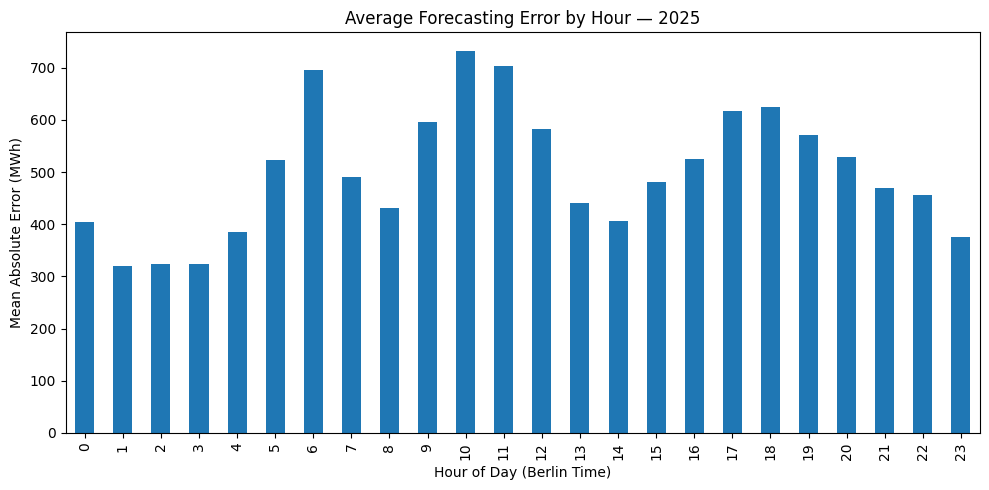

In [19]:

# Create a dataframe to analyze test predictions
error_df = test_df[
    ["timestamp_berlin", "grid_load_mwh", "hour",
     "day_of_week", "month"]
].copy()

error_df["predicted_mwh"] = final_pred

# Calculate prediction errors
error_df["error"] = (
    error_df["grid_load_mwh"] - error_df["predicted_mwh"]
)

error_df["absolute_error"] = error_df["error"].abs()

# Display 10 largest forecasting errors
print("TOP 10 LARGEST PREDICTION ERRORS")
display(
    error_df.sort_values(
        "absolute_error", ascending=False
    ).head(10)
)

# Calculate average error by hour
hourly_errors = error_df.groupby("hour")[
    "absolute_error"
].mean()

# Visualize hourly forecasting error
plt.figure(figsize=(10, 5))
hourly_errors.plot(kind="bar")

plt.title("Average Forecasting Error by Hour — 2025")
plt.xlabel("Hour of Day (Berlin Time)")
plt.ylabel("Mean Absolute Error (MWh)")
plt.tight_layout()
plt.show()


,Feature,Importance (MWh),Std Dev
4,lag_1,9759.023983,98.185017
0,hour,1791.102136,15.925379
6,lag_168,174.129460,3.973917
5,lag_24,137.802967,2.414123
1,day_of_week,136.403262,2.852249
2,month,49.900740,0.933239
3,is_weekend,0.000000,0.000000


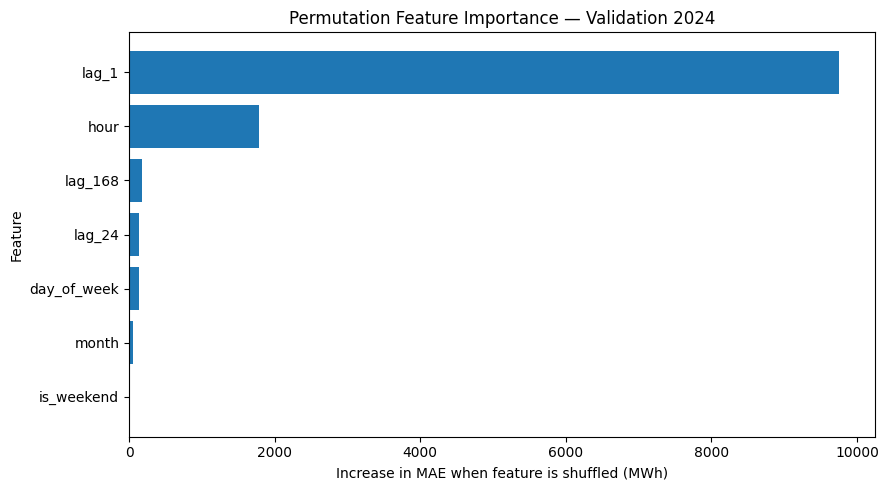

In [20]:

from sklearn.inspection import permutation_importance

# Explain the model trained only on 2023
importance = permutation_importance(
    tuned_model,
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance (MWh)": importance.importances_mean,
    "Std Dev": importance.importances_std
}).sort_values("Importance (MWh)", ascending=False)

display(importance_df)

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance (MWh)"]
)

plt.gca().invert_yaxis()

plt.title("Permutation Feature Importance — Validation 2024")
plt.xlabel("Increase in MAE when feature is shuffled (MWh)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [21]:

import joblib
from pathlib import Path

# Create model directory if needed
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save final trained model
joblib.dump(
    final_model,
    model_dir / "electricity_forecasting_model.joblib"
)

# Save feature names in their correct order
joblib.dump(
    features,
    model_dir / "feature_names.joblib"
)

print("Model saved successfully!")
print("Saved features:", features)
print("Model directory:", model_dir.resolve())


Model saved successfully!
Saved features: ['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168']
Model directory: /Users/mujtaba/Desktop/germany-electricity-demand-forecasting/models


In [22]:

import joblib
import numpy as np

# Load saved model and feature names
loaded_model = joblib.load(
    "models/electricity_forecasting_model.joblib"
)

loaded_features = joblib.load(
    "models/feature_names.joblib"
)

# Predict the first 10 test observations
loaded_predictions = loaded_model.predict(
    X_test[loaded_features].head(10)
)

# Compare with the original model predictions
original_predictions = final_pred[:10]

print("Predictions match:",
      np.allclose(loaded_predictions, original_predictions))

print("\nSaved model predictions:")
print(np.round(loaded_predictions, 2))

print("\nFeatures:", loaded_features)


Predictions match: True

Saved model predictions:
[46416.93 46086.55 46408.49 46067.11 46069.87 46365.37 48862.71 46698.76
 47069.2  50049.06]

Features: ['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168']


In [23]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("CSV files found:")
print(list(Path.cwd().rglob("*.csv")))

Current folder: /Users/mujtaba/Desktop/germany-electricity-demand-forecasting
CSV files found:
[PosixPath('/Users/mujtaba/Desktop/germany-electricity-demand-forecasting/data/raw/electricity_data.csv'), PosixPath('/Users/mujtaba/Desktop/germany-electricity-demand-forecasting/data/raw/.ipynb_checkpoints/electricity_data-checkpoint.csv')]


In [24]:

from pathlib import Path

project_files = [
    "data/raw/electricity_data.csv",
    "models/electricity_forecasting_model.joblib",
    "models/feature_names.joblib",
    "notebooks/01_data_inspection.ipynb"
]

for file in project_files:
    path = Path(file)
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {file}")


FOUND: data/raw/electricity_data.csv
FOUND: models/electricity_forecasting_model.joblib
FOUND: models/feature_names.joblib
FOUND: notebooks/01_data_inspection.ipynb


In [25]:

import pandas
import numpy
import matplotlib
import sklearn
import joblib

print("pandas==", pandas.__version__, sep="")
print("numpy==", numpy.__version__, sep="")
print("matplotlib==", matplotlib.__version__, sep="")
print("scikit-learn==", sklearn.__version__, sep="")
print("joblib==", joblib.__version__, sep="")


pandas==2.3.3
numpy==2.2.5
matplotlib==3.10.3
scikit-learn==1.8.0
joblib==1.5.0


In [26]:

from pathlib import Path

requirements = """pandas==2.3.3
numpy==2.2.5
matplotlib==3.10.3
scikit-learn==1.8.0
joblib==1.5.0
"""

Path("requirements.txt").write_text(requirements)

print("requirements.txt created successfully!")
print(Path("requirements.txt").read_text())


requirements.txt created successfully!
pandas==2.3.3
numpy==2.2.5
matplotlib==3.10.3
scikit-learn==1.8.0
joblib==1.5.0



In [27]:

from pathlib import Path

gitignore = """# Python
__pycache__/
*.pyc
.venv/
venv/
.env

# Jupyter
.ipynb_checkpoints/

# macOS
.DS_Store

# Temporary files
*.log
*.tmp
"""

Path(".gitignore").write_text(gitignore)

print(".gitignore created successfully!")


.gitignore created successfully!


In [28]:

from pathlib import Path

readme = """# German Electricity Demand Forecasting

### Machine Learning | Time-Series Forecasting | Python | scikit-learn

A machine learning project predicting Germany's electricity demand
one hour ahead using official historical grid-load data from SMARD.

## 1. Project Overview

Electricity demand forecasting supports power-system planning and
operational decision-making.

This project develops and evaluates machine learning models for
rolling one-hour-ahead electricity demand forecasting.

## 2. Dataset

**Source:** Bundesnetzagentur | SMARD.de
https://www.smard.de/

- Period: January 2023 – December 2025
- Observations: 26,304 hourly records
- Region: Germany
- Target: Actual grid load (MWh)
- Missing target values: 0 after conversion

The data is reused with attribution under CC BY 4.0.

## 3. Methodology

### Data Preparation
- Loaded and validated original SMARD CSV data
- Corrected numerical formatting
- Converted local timestamps to UTC
- Handled daylight-saving-time transitions
- Verified continuous hourly observations

### Feature Engineering
- Hour, day of week, month and weekend indicator
- Previous-hour electricity demand (lag_1)
- Previous-day demand (lag_24)
- Previous-week demand (lag_168)

All lag features use previously observed demand.

### Chronological Data Split
- Training: 2023
- Validation: 2024
- Testing: 2025

Final model training used 2023–2024.

### Models Evaluated
- Persistence baseline
- Ridge Regression
- Random Forest Regression
- Histogram-based Gradient Boosting

TimeSeriesSplit and RandomizedSearchCV were used for
cross-validation and hyperparameter tuning.

## 4. Model Evaluation

### Validation Results (2024)

| Model | MAE (MWh) | RMSE (MWh) |
|---|---:|---:|
| Persistence | 1,757.88 | 2,319.90 |
| Ridge Regression | 1,398.80 | 1,842.12 |
| Random Forest | 604.18 | 848.43 |
| Gradient Boosting | 514.83 | 697.04 |
| Tuned Gradient Boosting | 495.31 | 671.64 |

### Final Test Results (2025)

| Model | MAE (MWh) | RMSE (MWh) |
|---|---:|---:|
| Persistence | 1,779.00 | 2,342.67 |
| Tuned Gradient Boosting | 500.46 | 666.45 |

**MAE reduction versus persistence: 71.87%.**

The final model was evaluated on 8,760 test observations.

## 5. Key Findings

- Gradient Boosting outperformed the other evaluated approaches
  on the 2024 validation dataset.
- Previous-hour demand was the most important predictor
  according to permutation importance.
- Larger forecasting errors occurred around several holidays.
- Average errors were relatively high during some morning hours.
- The model showed similar MAE on validation and test data.

## 6. Limitations

- Forecasts assume recent actual grid-load observations are available.
- This is rolling one-hour-ahead forecasting, not a full-year
  forecast generated without new observations.
- Holiday and weather information were not included.
- Results cover the historical period studied and may not
  generalize to changing market conditions.
- Permutation importance is not a causal explanation.
- Hyperparameter search was limited to selected configurations.

## 7. Project Structure

```text
germany-electricity-demand-forecasting/
├── data/
│   └── raw/
│       └── electricity_data.csv
├── notebooks/
│   └── 01_data_inspection.ipynb
├── models/
│   ├── electricity_forecasting_model.joblib
│   └── feature_names.joblib
├── requirements.txt
├── .gitignore
└── README.md
```

## 8. Reproducibility

1. Clone this repository.
2. Create a Python environment.
3. Install dependencies:

```bash
pip install -r requirements.txt
```

4. Launch Jupyter from the repository root.
5. Open notebooks/01_data_inspection.ipynb.
6. Verify that the notebook's working directory is the
   repository root before running its cells.

The saved model was created using scikit-learn 1.8.0.
Only load model files from trusted sources.

## 9. Technologies

Python, Pandas, NumPy, Matplotlib, scikit-learn,
Jupyter Notebook, Joblib.

## 10. Author

Muhammad Mujtaba
B.Sc. Computer Science and Digitalisation
Berlin School of Business and Innovation, Germany

GitHub: https://github.com/Mujitabaa
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md created successfully!")
print("File size:", Path("README.md").stat().st_size, "bytes")


README.md created successfully!
File size: 4166 bytes


In [29]:

from pathlib import Path

files = [
    "data/raw/electricity_data.csv",
    "models/electricity_forecasting_model.joblib",
    "models/feature_names.joblib",
    "notebooks/01_data_inspection.ipynb",
    "README.md",
    "requirements.txt",
    ".gitignore"
]

for filename in files:
    path = Path(filename)

    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"{filename}: {size_mb:.2f} MB")
    else:
        print(f"MISSING: {filename}")


data/raw/electricity_data.csv: 2.01 MB
models/electricity_forecasting_model.joblib: 0.70 MB
models/feature_names.joblib: 0.00 MB
notebooks/01_data_inspection.ipynb: 0.15 MB
README.md: 0.00 MB
requirements.txt: 0.00 MB
.gitignore: 0.00 MB
